# Trabalho Computacional de Estatística — Primeira Parte
## Estatística Descritiva

**Linguagem:** Python 3

**Integrantes:**
- Ana Júlia Lisboa de Sousa
- Davi Silva Pinheiro
- Filipe Freitas Campos
- Miguel Pereira Borges
- Victor Hugo Gabriel dos Reis
- Vitor Eduardo Gonçalves Dumont

### Organização do notebook

| Seção | Conteúdo |
|---|---|
| **0. Configuração** | Importação de todas as bibliotecas |
| **Questão 1** | Algoritmos próprios das medidas descritivas. Formam a "biblioteca" do trabalho e são reutilizados nas outras questões |
| **Funções gráficas** | Funções de gráficos compartilhadas pelas Questões 2, 3 e 4 |
| **Questão 2** | Erros de impressão: gráficos, histograma e ramo-e-folhas |
| **Questão 3** | Conjunto de dados C1 (restaurantes do Zomato): gráficos e comparação com uma biblioteca |
| **Questão 4** | Histograma com classes desiguais (densidade) e comparação com o gabarito |

> **Como executar:** as células dependem umas das outras (por exemplo, a Questão 3 usa as funções da Questão 1). Por isso, execute o notebook **em ordem, do início ao fim** (*Run All*). As dependências estão em `requirements.txt` e podem ser instaladas com `pip install -r requirements.txt`.

### 0. Configuração: bibliotecas utilizadas

Todas as importações ficam reunidas na célula abaixo, para que as dependências do trabalho fiquem visíveis em um só lugar.

| Biblioteca | Tipo | Para que é usada | Onde |
|---|---|---|---|
| `math` | padrão do Python | `log10` e `ceil` na regra de Sturges (número e amplitude das classes do histograma) | Questão 2 |
| `random` | padrão do Python | Geração de listas aleatórias para testar os algoritmos da Questão 1, e pequeno deslocamento vertical (*jitter*) que evita a sobreposição de pontos no gráfico de dispersão unidimensional | Questões 1 e 3 |
| `statistics` | padrão do Python | Funções prontas (`mean`, `median`, `multimode`, `quantiles`, `variance`, `stdev`) usadas para provar o resultado dos nossos algoritmos | Questão 1 (conferência) |
| `matplotlib.pyplot` | externa | Construção de todos os gráficos (barras, setores, linhas, dispersão e histogramas) | Questões 2, 3 e 4 |
| `polars` | externa | Leitura do arquivo CSV e filtragem dos dados. Também fornece `mean()` e `std()`, usadas como referência para validar os nossos algoritmos | Questão 3 |

Os algoritmos da Questão 1 não usam nenhuma dessas bibliotecas: as medidas descritivas são calculadas com código próprio, como pede o enunciado. O `statistics` é usado na célula de conferência.

In [17]:
# 0. Configuração: importações

import math     
import random   
import statistics  

# Bibliotecas externas (pip install -r requirements.txt)
import matplotlib.pyplot as plt   
import polars as pl              

# --- Parâmetros globais -------------------------------------------------------
# Semente fixa: o jitter fica igual a cada execução, então os gráficos são
# reprodutíveis.
random.seed(0)

print("Bibliotecas carregadas")

Bibliotecas carregadas


### Questão 1
<img src="imagens/1.png" width="600" alt="Questão 1">

**Resposta:**

Todas as medidas foram implementadas com algoritmos próprios, sem funções estatísticas de bibliotecas (`statistics`, `numpy`) e sem `min`, `max` ou `sorted`. A ordenação também é nossa (insertion sort).

- **Funções básicas:** `ordenar`, `contar_frequencias`, `calcular_minimo_maximo` e `calcular_separatriz` são usadas pelas medidas abaixo e também reaproveitadas nas Questões 2 e 3.
- **Amplitude:** maior valor menos o menor, encontrados em uma única passada pela lista.
- **Moda:** contagem de frequências com um dicionário. A função devolve todos os valores de frequência máxima (multimodal) ou indica *amodal* quando todos os valores aparecem o mesmo número de vezes.
- **Mediana:** elemento central (n ímpar) ou média dos dois centrais (n par).
- **1º quartil:** posição $(n+1)\cdot 0{,}25$ com interpolação linear entre os vizinhos.
- **Variância, desvio padrão e CV:** são mostrados nas versões amostral ($n-1$) e populacional ($n$).

Para analisar outro conjunto, basta trocar a lista `amostra`. Na célula seguinte, os resultados são comparados com as funções prontas do módulo `statistics`.

In [18]:
# --- Funções básicas (reutilizadas pelas medidas e pelas outras questões) ----

# Devolve uma cópia ordenada da lista (insertion sort).
def ordenar(dados):
    ordenados = list(dados)
    for i in range(1, len(ordenados)):
        atual = ordenados[i]
        j = i - 1
        while j >= 0 and ordenados[j] > atual:
            ordenados[j + 1] = ordenados[j]
            j -= 1
        ordenados[j + 1] = atual
    return ordenados

# Devolve um dicionário {valor: frequência absoluta}.
def contar_frequencias(dados):
    frequencias = {}
    for x in dados:
        frequencias[x] = frequencias.get(x, 0) + 1
    return frequencias

# Devolve (menor, maior) percorrendo a lista uma única vez.
def calcular_minimo_maximo(dados):
    menor = maior = dados[0]
    for x in dados:
        if x < menor:
            menor = x
        if x > maior:
            maior = x
    return menor, maior


#   Separatriz de ordem p (0 < p < 1), por exemplo p = 0,25 para o 1º quartil.
#   Método: posição P = (n + 1) · p, com interpolação linear entre os dois valores vizinhos
def calcular_separatriz(dados, p):
    ordenados = ordenar(dados)
    n = len(ordenados)
    posicao = (n + 1) * p          # posição a partir de 1
    if posicao <= 1:
        return ordenados[0]
    if posicao >= n:
        return ordenados[-1]
    k = int(posicao)               # parte inteira da posição
    fracao = posicao - k
    return ordenados[k - 1] + fracao * (ordenados[k] - ordenados[k - 1])


# --- Medidas de posição -------------------------------------------------------

# a) Amplitude = maior valor - menor valor
def calcular_amplitude(dados):
    menor, maior = calcular_minimo_maximo(dados)
    return maior - menor

# b) Média aritmética = soma dos valores / quantidade de valores
def calcular_media(dados):
    return sum(dados) / len(dados)

# c) Moda = valor(es) de maior frequência.
#    Devolve uma lista: 1 elemento (unimodal), vários (multimodal) ou
#    lista vazia (amodal, quando todos os valores têm a mesma frequência).
def calcular_moda(dados):
    frequencias = contar_frequencias(dados)
    _, maior_freq = calcular_minimo_maximo(list(frequencias.values()))
    modas = [valor for valor, f in frequencias.items() if f == maior_freq]
    if len(modas) == len(frequencias):
        return []
    return ordenar(modas)

# d) Mediana = valor central dos dados ordenados
#    n ímpar: elemento do meio; n par: média dos dois elementos centrais
def calcular_mediana(dados):
    ordenados = ordenar(dados)
    n = len(ordenados)
    meio = n // 2
    if n % 2 == 1:
        return ordenados[meio]
    return (ordenados[meio - 1] + ordenados[meio]) / 2

# e) 1º quartil (25%)
def calcular_q1(dados):
    return calcular_separatriz(dados, 0.25)


# --- Medidas de dispersão -----------------------------------------------------

# f) Variância (a amostral divide por n - 1 e a populacional divide por n)
def calcular_variancia(dados, amostral=True):
    media = calcular_media(dados)
    soma_quadrados = sum((x - media) ** 2 for x in dados)
    n = len(dados)
    return soma_quadrados / (n - 1 if amostral else n)

# g) Desvio padrão = raiz quadrada da variância
def calcular_desvio_padrao(dados, amostral=True):
    return calcular_variancia(dados, amostral) ** 0.5

# h) Coeficiente de variação (%) = desvio padrão / média · 100
def calcular_coeficiente_variacao(dados, amostral=True):
    media = calcular_media(dados)
    if media == 0:
        return float("nan")  # CV indefinido quando a média é zero
    return calcular_desvio_padrao(dados, amostral) / abs(media) * 100


# --- Algoritmo principal: recebe a lista e mostra todas as medidas ------------

def analisar_dados(dados):
    if not dados or len(dados) < 2:
        raise ValueError("Forneça pelo menos 2 dados na lista.")

    modas = calcular_moda(dados)
    texto_moda = ", ".join(str(m) for m in modas) if modas else "amodal"

    print(f"Dados informados (ordenados): {ordenar(dados)}  (n = {len(dados)})\n")
    print("--- Medidas de Posição ---")
    print(f"a) Amplitude: {calcular_amplitude(dados)}")
    print(f"b) Média: {calcular_media(dados):.2f}")
    print(f"c) Moda: {texto_moda}")
    print(f"d) Mediana: {calcular_mediana(dados):.2f}")
    print(f"e) 1º Quartil (25%): {calcular_q1(dados):.2f}")

    print("\n--- Medidas de Dispersão ---")
    for rotulo, funcao, casas, sufixo in [
        ("f) Variância", calcular_variancia, 4, ""),
        ("g) Desvio Padrão", calcular_desvio_padrao, 4, ""),
        ("h) Coeficiente de Variação", calcular_coeficiente_variacao, 2, "%"),
    ]:
        amostral = funcao(dados, amostral=True)
        populacional = funcao(dados, amostral=False)
        print(f"{rotulo}: {amostral:.{casas}f}{sufixo} (amostral) | "
              f"{populacional:.{casas}f}{sufixo} (populacional)")


# Exemplo de uso. Para analisar outro conjunto, basta trocar a lista.
amostra = [12, 15, 12, 18, 20, 22, 15, 14, 17, 12]
analisar_dados(amostra)

Dados informados (ordenados): [12, 12, 12, 14, 15, 15, 17, 18, 20, 22]  (n = 10)

--- Medidas de Posição ---
a) Amplitude: 10
b) Média: 15.70
c) Moda: 12
d) Mediana: 15.00
e) 1º Quartil (25%): 12.00

--- Medidas de Dispersão ---
f) Variância: 12.2333 (amostral) | 11.0100 (populacional)
g) Desvio Padrão: 3.4976 (amostral) | 3.3181 (populacional)
h) Coeficiente de Variação: 22.28% (amostral) | 21.13% (populacional)


In [19]:
# Questão 1: conferência dos nossos algoritmos com o módulo statistics

# Retorna lista com nome da medida, resultado com nossas funções e resultado a partir das funções da biblioteca.
def comparar_com_statistics(dados):
    return [
        ("a) Amplitude", calcular_amplitude(dados), max(dados) - min(dados)),
        ("b) Média", calcular_media(dados), statistics.mean(dados)),
        ("c) Moda", calcular_moda(dados), statistics.multimode(dados)),
        ("d) Mediana", calcular_mediana(dados), statistics.median(dados)),
        ("e) 1º Quartil", calcular_q1(dados), statistics.quantiles(dados, n=4, method="exclusive")[0]),
        ("f) Variância", calcular_variancia(dados), statistics.variance(dados)),
        ("g) Desvio padrão", calcular_desvio_padrao(dados), statistics.stdev(dados)),
        ("h) CV (%)", calcular_coeficiente_variacao(dados), statistics.stdev(dados) / statistics.mean(dados) * 100),
    ]


def resultados_iguais(proprio, biblioteca):
    if isinstance(proprio, list):
        return proprio == sorted(biblioteca)
    return abs(proprio - biblioteca) < 1e-9


# 1) Comparação lado a lado com a amostra do exemplo
print(f"{'Medida':<18} | {'Nosso algoritmo':>16} | {'statistics':>16} | Igual?")
print("-" * 66)
for medida, proprio, biblioteca in comparar_com_statistics(amostra):
    if isinstance(proprio, list):
        p, b = str(proprio), str(sorted(biblioteca))
    else:
        p, b = f"{proprio:.4f}", f"{biblioteca:.4f}"
    print(f"{medida:<18} | {p:>16} | {b:>16} | {'sim' if resultados_iguais(proprio, biblioteca) else 'NÃO'}")

# 2) Teste com várias listas aleatórias, para provar em diversos casos.
#    Usamos listas sem empate na frequência máxima entre todos os valores,
#    porque nesse caso a nossa moda devolve "amodal" e o multimode devolve
#    todos os valores.
testes, divergencias = 0, 0
for _ in range(500):
    lista = [random.randint(0, 50) for _ in range(random.randint(3, 60))]
    if len(statistics.multimode(lista)) == len(set(lista)):
        continue
    testes += 1
    if not all(resultados_iguais(p, b) for _, p, b in comparar_com_statistics(lista)):
        divergencias += 1

print(f"\nListas aleatórias testadas: {testes} | divergências: {divergencias}")

Medida             |  Nosso algoritmo |       statistics | Igual?
------------------------------------------------------------------
a) Amplitude       |          10.0000 |          10.0000 | sim
b) Média           |          15.7000 |          15.7000 | sim
c) Moda            |             [12] |             [12] | sim
d) Mediana         |          15.0000 |          15.0000 | sim
e) 1º Quartil      |          12.0000 |          12.0000 | sim
f) Variância       |          12.2333 |          12.2333 | sim
g) Desvio padrão   |           3.4976 |           3.4976 | sim
h) CV (%)          |          22.2778 |          22.2778 | sim

Listas aleatórias testadas: 444 | divergências: 0


### Funções gráficas compartilhadas

Os gráficos das Questões 2, 3 e 4 seguem os mesmos padrões. Para não repetir código, as partes comuns ficam reunidas aqui:

| Função | O que faz | Usada em |
|---|---|---|
| `titulo_secao` | Imprime o cabeçalho de cada questão | Q2, Q3, Q4 |
| `configurar_eixos` | Título, rótulos dos eixos e grade | todos os gráficos |
| `rotular` | Escreve o valor (ou %) acima de cada barra | Q2, Q3, Q4 |
| `grafico_barras` | Gráfico de barras de frequências (categorias numéricas ou textuais) | Q2 (a), Q3 (b) |
| `grafico_dispersao_unidimensional` | Pontos sobre um eixo: empilhados (poucos valores repetidos) ou com *jitter* (muitos valores) | Q2 (a), Q3 (d) |
| `desenhar_histograma` | Histograma a partir de limites de classe e alturas. Aceita classes de amplitudes diferentes | Q2 (b), Q4 |

As funções devolvem o eixo (`ax`). Assim, cada questão ainda pode fazer ajustes específicos antes de chamar `plt.show()`.

In [20]:
# =============================================================================
# Funções gráficas compartilhadas (Questões 2, 3 e 4)
# =============================================================================

#   Cabeçalho padronizado na saída de cada questão.
def titulo_secao(texto):
    print("=" * 70)
    print(texto)
    print("=" * 70)

#   Título, rótulos dos eixos e grade tracejada (grade=None desliga).
def configurar_eixos(ax, titulo, xlabel, ylabel=None, grade="y"):
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    if grade:
        ax.grid(axis=grade, linestyle="--", alpha=0.5)
        ax.set_axisbelow(True)

#   Escreve um texto acima de cada barra (por padrão, a própria altura).
#   Barras de altura zero ficam sem rótulo. O eixo y ganha 12% de folga.
def rotular(ax, posicoes_x, alturas, textos=None):
    topo = calcular_minimo_maximo(alturas)[1]
    textos = alturas if textos is None else textos
    for x, h, t in zip(posicoes_x, alturas, textos):
        if h:
            ax.text(x, h + topo * 0.01, str(t), ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, topo * 1.12)

#    Gráfico de barras de frequências. As categorias podem ser números ou textos.
def grafico_barras(categorias, contagens, titulo, xlabel, ylabel, rotacao=0):
    fig, ax = plt.subplots(figsize=(10, 5)) 
    posicoes = range(len(categorias))
    ax.bar(posicoes, contagens, width=0.6, edgecolor="black")
    ax.set_xticks(posicoes, [str(c) for c in categorias], rotation=rotacao)
    rotular(ax, posicoes, contagens)
    configurar_eixos(ax, titulo, xlabel, ylabel)
    return ax

#   Cada ponto é uma observação, posicionada sobre o eixo x.
#   empilhar=True : valores repetidos são empilhados (Questão 2).
#   empilhar=False: deslocamento vertical aleatório (jitter) com transparência (Questão 3).
def grafico_dispersao_unidimensional(valores, titulo, xlabel, empilhar=True):
    fig, ax = plt.subplots(figsize=(10, 3.5))
    if empilhar:
        frequencias = contar_frequencias(valores)
        for valor, fi in frequencias.items():
            ax.scatter([valor] * fi, range(1, fi + 1), s=60, color="C0", edgecolor="black")  # mesma cor em todas as colunas
        menor, maior = calcular_minimo_maximo(valores)
        ax.set_xticks(range(menor, maior + 1))
        ax.set_ylim(0, calcular_minimo_maximo(list(frequencias.values()))[1] + 1)
    else:
        jitter = [random.uniform(-0.1, 0.1) for _ in valores]
        ax.scatter(valores, jitter, s=30, alpha=0.5, edgecolor="black", linewidth=0.3)
        ax.set_ylim(-0.5, 0.5)
    ax.set_yticks([])
    for lado in ("left", "right", "top"):    # só o eixo x interessa neste gráfico
        ax.spines[lado].set_visible(False)
    configurar_eixos(ax, titulo, xlabel, grade=None)
    return ax

#   Histograma a partir dos limites das classes [li, ls) e da altura de cada
#   retângulo. A largura de cada retângulo é ls - li, então classes de
#   amplitudes diferentes são desenhadas corretamente (Questão 4).
def desenhar_histograma(limites, alturas, titulo, xlabel, ylabel, rotulos=None):
    inicios = limites[:-1]
    larguras = [ls - li for li, ls in zip(limites[:-1], limites[1:])]
    centros = [li + w / 2 for li, w in zip(inicios, larguras)]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(inicios, alturas, width=larguras, align="edge", edgecolor="black")
    ax.set_xticks(limites)
    rotular(ax, centros, alturas, rotulos)
    configurar_eixos(ax, titulo, xlabel, ylabel)
    return ax

### Questão 2
<img src="imagens/2.png" width="600" alt="Questão 2">

**Resposta:**

Os 50 valores foram transcritos da tabela do enunciado e conferidos linha a linha.

- **(a)** O número de erros é uma variável quantitativa **discreta**, por isso usamos uma tabela de frequências, um gráfico de barras e um gráfico de dispersão unidimensional.
- **(b)** O histograma usa classes de amplitude 3, obtida pela regra de Sturges. O ramo-e-folhas aparece na forma simples e com os ramos desdobrados.

**Interpretação:** os erros variam de 5 a 22, com média 10,74, mediana 11 e moda 12 (desvio padrão amostral ≈ 3,55). A maior parte dos dias fica entre 7 e 14 erros. A distribuição tem uma cauda à direita: pelo critério de 1,5·IQR ($Q_1 = 8$, $Q_3 = 13{,}25$, limite superior ≈ 21,1), o valor 22 é atípico, e 19 também se afasta bastante do restante.

Questão 2: erros de impressão na 1ª página (50 dias)
Medidas descritivas (algoritmos da Questão 1):

Dados informados (ordenados): [5, 5, 6, 6, 6, 7, 7, 7, 7, 7, 8, 8, 8, 8, 8, 8, 8, 9, 9, 10, 10, 10, 10, 10, 11, 11, 11, 11, 12, 12, 12, 12, 12, 12, 12, 12, 12, 13, 14, 14, 14, 14, 14, 14, 14, 15, 15, 16, 19, 22]  (n = 50)

--- Medidas de Posição ---
a) Amplitude: 17
b) Média: 10.74
c) Moda: 12
d) Mediana: 11.00
e) 1º Quartil (25%): 8.00

--- Medidas de Dispersão ---
f) Variância: 12.6045 (amostral) | 12.3524 (populacional)
g) Desvio Padrão: 3.5503 (amostral) | 3.5146 (populacional)
h) Coeficiente de Variação: 33.06% (amostral) | 32.72% (populacional)

3º Quartil: 13.25 | IQR = 5.25 | limite p/ valores atípicos (Q3 + 1,5·IQR) = 21.12

--- Item (a) ---

 Erros |  fi |      fr |  Fi |      Fr
----------------------------------------
     5 |   2 |   4.00% |   2 |   4.00%
     6 |   3 |   6.00% |   5 |  10.00%
     7 |   5 |  10.00% |  10 |  20.00%
     8 |   7 |  14.00% |  17 |  34.00%
   

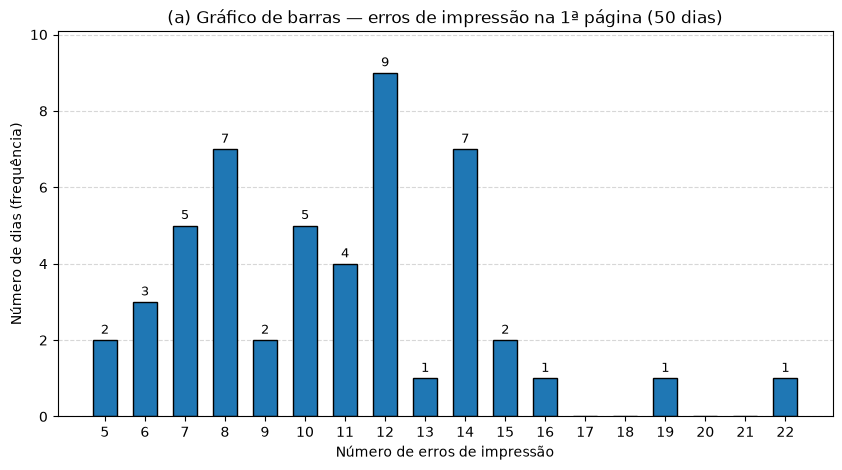

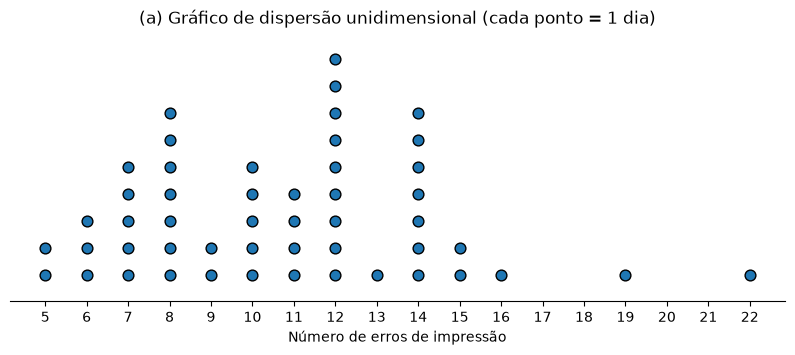


--- Item (b) ---

n = 50, mínimo = 5, máximo = 22, amplitude total = 17
Sturges: k = 1 + 3,3·log10(50) ≈ 6.61 ≈ 7 -> h = ceil(17/7) = 3 -> 6 classes cobrem de 5 a 22

     Classe |    xi |  fi |      fr |  Fi
------------------------------------------
  5 |-- 8    |   6.5 |  10 |  20.00% |  10
  8 |-- 11   |   9.5 |  14 |  28.00% |  24
 11 |-- 14   |  12.5 |  14 |  28.00% |  38
 14 |-- 17   |  15.5 |  10 |  20.00% |  48
 17 |-- 20   |  18.5 |   1 |   2.00% |  49
 20 |-- 23   |  21.5 |   1 |   2.00% |  50
------------------------------------------
      Total |       |  50 | 100.00%


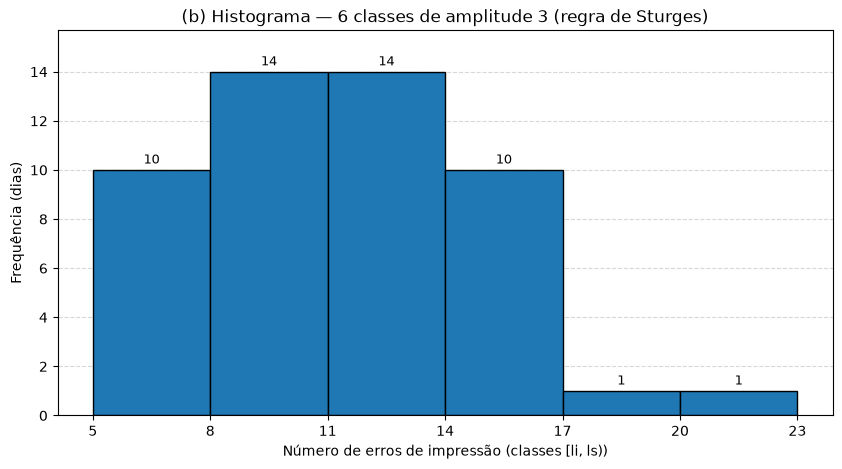


Ramo-e-folhas (ramo = dezena, folha = unidade)   Ex.: 1 | 4 = 14 erros
  0 | 5 5 6 6 6 7 7 7 7 7 8 8 8 8 8 8 8 9 9   (19)
  1 | 0 0 0 0 0 1 1 1 1 2 2 2 2 2 2 2 2 2 3 4 4 4 4 4 4 4 5 5 6 9   (30)
  2 | 2   (1)

Ramo-e-folhas com ramos desdobrados  (* = folhas 0–4, . = folhas 5–9)
 0. | 5 5 6 6 6 7 7 7 7 7 8 8 8 8 8 8 8 9 9   (19)
 1* | 0 0 0 0 0 1 1 1 1 2 2 2 2 2 2 2 2 2 3 4 4 4 4 4 4 4   (26)
 1. | 5 5 6 9   (4)
 2* | 2   (1)


In [21]:
# Questão 2: erros de impressão na 1ª página de um jornal (50 dias)


# Dados transcritos linha a linha da tabela do enunciado
DADOS_Q2 = [
    8, 11, 8, 12, 14, 13, 11, 14, 14, 15,
    6, 10, 14, 19, 6, 12, 7, 5, 8, 8,
    10, 16, 10, 12, 12, 8, 11, 6, 7, 12,
    7, 10, 14, 5, 12, 7, 9, 12, 11, 9,
    14, 8, 14, 8, 12, 10, 12, 22, 7, 15,
]
assert len(DADOS_Q2) == 50, "Deveriam ser 50 observações"


def tabela_frequencias(dados):
    """Tabela de frequências simples, relativas e acumuladas (variável discreta)."""
    n = len(dados)
    frequencias = contar_frequencias(dados)
    print(f"{'Erros':>6} | {'fi':>3} | {'fr':>7} | {'Fi':>3} | {'Fr':>7}")
    print("-" * 40)
    acumulada = 0
    for valor in ordenar(frequencias):
        fi = frequencias[valor]
        acumulada += fi
        print(f"{valor:>6} | {fi:>3} | {fi / n:>7.2%} | {acumulada:>3} | {acumulada / n:>7.2%}")
    print("-" * 40)
    print(f"{'Total':>6} | {n:>3} | {1:>7.2%}")
    return frequencias


def classes_sturges(dados):
    """Limites das classes [li, ls) pela regra de Sturges: k = 1 + 3,3·log10(n).
    Amplitude de classe h = ceil(amplitude total / k)."""
    n = len(dados)
    menor, maior = calcular_minimo_maximo(dados)
    amplitude_total = maior - menor
    k_sturges = round(1 + 3.3 * math.log10(n))
    h = math.ceil(amplitude_total / k_sturges)
    k = amplitude_total // h + 1               # classes necessárias para cobrir até o máximo
    limites = [menor + i * h for i in range(k + 1)]

    print(f"n = {n}, mínimo = {menor}, máximo = {maior}, amplitude total = {amplitude_total}")
    print(f"Sturges: k = 1 + 3,3·log10({n}) ≈ {1 + 3.3 * math.log10(n):.2f} ≈ {k_sturges} "
          f"-> h = ceil({amplitude_total}/{k_sturges}) = {h} -> {k} classes cobrem de {menor} a {maior}")
    return limites, h


def frequencias_por_classe(dados, limites):
    """Conta quantos valores caem em cada classe [li, ls) e imprime a tabela."""
    n = len(dados)
    print(f"\n{'Classe':>11} | {'xi':>5} | {'fi':>3} | {'fr':>7} | {'Fi':>3}")
    print("-" * 42)
    freqs, acumulada = [], 0
    for li, ls in zip(limites[:-1], limites[1:]):
        fi = sum(1 for x in dados if li <= x < ls)
        acumulada += fi
        freqs.append(fi)
        print(f"{li:>3} |-- {ls:<4} | {(li + ls) / 2:>5.1f} | {fi:>3} | {fi / n:>7.2%} | {acumulada:>3}")
    print("-" * 42)
    print(f"{'Total':>11} | {'':>5} | {n:>3} | {1:>7.2%}")
    return freqs


def ramo_e_folhas(dados, desdobrado=False):
    """Linhas do diagrama (ramo = dezena, folha = unidade).
    Com desdobrado=True, cada ramo se divide em '*' (folhas 0–4) e '.' (folhas 5–9)."""
    ordenados = ordenar(dados)
    menor, maior = ordenados[0], ordenados[-1]
    linhas = []
    for ramo in range(menor // 10, maior // 10 + 1):
        folhas = [x % 10 for x in ordenados if x // 10 == ramo]
        if desdobrado:
            linhas.append((f"{ramo}*", [f for f in folhas if f <= 4]))
            linhas.append((f"{ramo}.", [f for f in folhas if f >= 5]))
        else:
            linhas.append((f"{ramo}", folhas))
    # descarta ramos vazios nas pontas
    while not linhas[0][1]:
        linhas.pop(0)
    while not linhas[-1][1]:
        linhas.pop()
    return [f"{r:>3} | {' '.join(map(str, f))}   ({len(f)})" for r, f in linhas]


# -----------------------------------------------------------------------------
titulo_secao("Questão 2: erros de impressão na 1ª página (50 dias)")

print("Medidas descritivas (algoritmos da Questão 1):\n")
analisar_dados(DADOS_Q2)
q1, q3 = calcular_separatriz(DADOS_Q2, 0.25), calcular_separatriz(DADOS_Q2, 0.75)
print(f"\n3º Quartil: {q3:.2f} | IQR = {q3 - q1:.2f} | "
      f"limite p/ valores atípicos (Q3 + 1,5·IQR) = {q3 + 1.5 * (q3 - q1):.2f}")

# - (a) Representação gráfica
# "Número de erros" é quantitativa DISCRETA, então usamos um gráfico de barras
# das frequências de cada valor e um gráfico de dispersão unidimensional.
print("\n--- Item (a) ---\n")
freq_q2 = tabela_frequencias(DADOS_Q2)

menor, maior = calcular_minimo_maximo(DADOS_Q2)
valores = list(range(menor, maior + 1))       # inclui valores com frequência 0
grafico_barras(valores, [freq_q2.get(v, 0) for v in valores],
               "(a) Gráfico de barras — erros de impressão na 1ª página (50 dias)",
               "Número de erros de impressão", "Número de dias (frequência)")
plt.show()

grafico_dispersao_unidimensional(DADOS_Q2,
                                 "(a) Gráfico de dispersão unidimensional (cada ponto = 1 dia)",
                                 "Número de erros de impressão", empilhar=True)
plt.show()

# --- (b) Histograma e ramo-e-folhas ---------------------------------------------
print("\n--- Item (b) ---\n")
limites_q2, h_q2 = classes_sturges(DADOS_Q2)
freqs_classes = frequencias_por_classe(DADOS_Q2, limites_q2)

desenhar_histograma(limites_q2, freqs_classes,
                    f"(b) Histograma — {len(freqs_classes)} classes de amplitude {h_q2} (regra de Sturges)",
                    "Número de erros de impressão (classes [li, ls))", "Frequência (dias)")
plt.show()

simples = ramo_e_folhas(DADOS_Q2)
desdobrado = ramo_e_folhas(DADOS_Q2, desdobrado=True)
print("\nRamo-e-folhas (ramo = dezena, folha = unidade)   Ex.: 1 | 4 = 14 erros")
print("\n".join(simples))
print("\nRamo-e-folhas com ramos desdobrados  (* = folhas 0–4, . = folhas 5–9)")
print("\n".join(desdobrado))

### Questão 3
<img src="imagens/3.png" width="600" alt="Questão 3">

**Resposta:**

**Conjunto C1:** dados de restaurantes cadastrados no Zomato, no arquivo `Zomato_Restauran_Dataset.csv`, que é entregue junto com o trabalho na raiz do repositório. Foram usados apenas os restaurantes com preço em dólar, para que os custos fossem comparáveis.

| Tipo | Variável | Gráfico |
|---|---|---|
| Qualitativa (ordinal) | `Rating text` (classificação da avaliação) | (a) setores |
| Qualitativa (nominal) | `City` (cidade) | (b) barras |
| Quantitativa discreta | `Average Cost for two` (custo para duas pessoas, em dólares inteiros) | (c) linhas (polígono de frequências) |
| Quantitativa discreta | `Votes` (número de avaliações) | (d) dispersão unidimensional |

Questão 3: restaurantes do Zomato (conjunto C1)
Arquivo importado: Zomato_Restauran_Dataset.csv  ->  100 linhas x 14 colunas
Após filtrar Currency == 'Dollar($)': 80 restaurantes



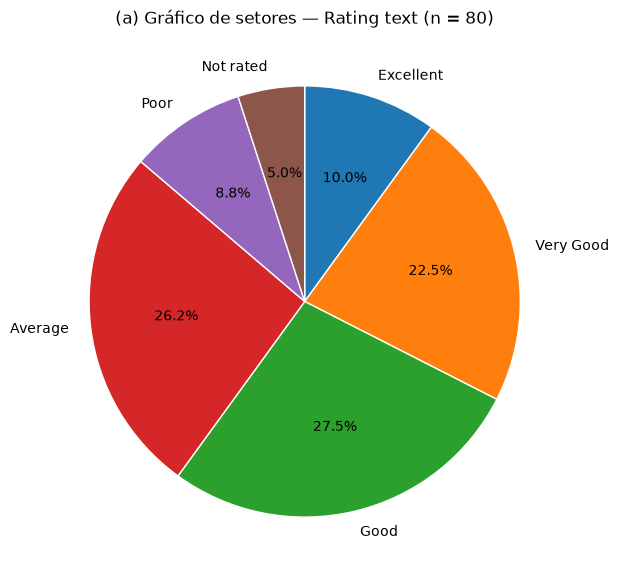

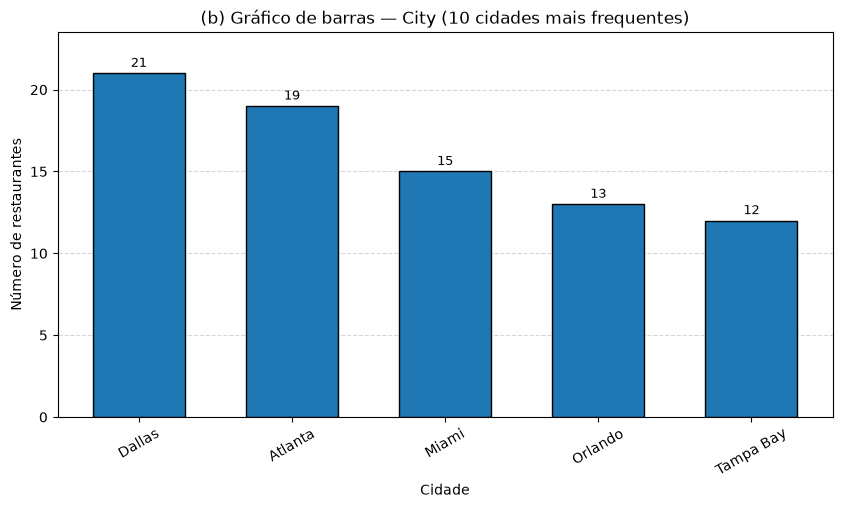

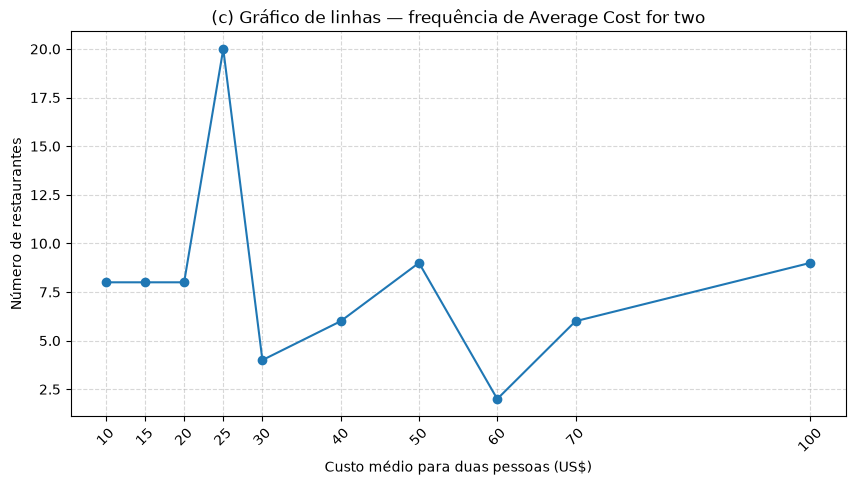

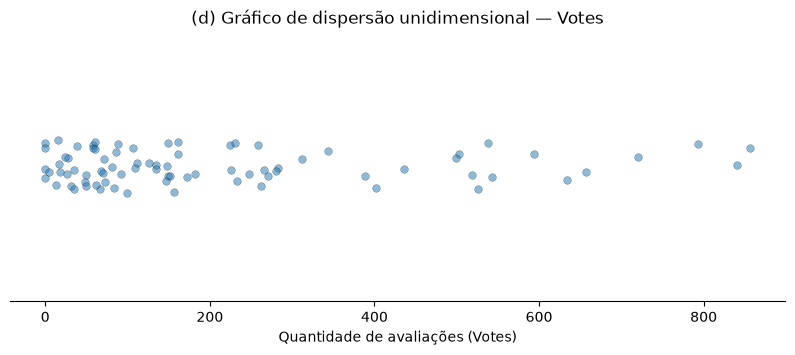

Comparação: algoritmo próprio (Questão 1) x Polars
Variável               | Medida        |      Próprio |       Polars |  Diferença
--------------------------------------------------------------------------------
Average Cost for two   | Média         |      38.8750 |      38.8750 |   0.00e+00
                       | Desvio padrão |      27.4896 |      27.4896 |   0.00e+00
Votes                  | Média         |     209.9500 |     209.9500 |   0.00e+00
                       | Desvio padrão |     217.7938 |     217.7938 |   0.00e+00


In [22]:
# Questão 3: conjunto de dados C1 (restaurantes do Zomato)

# ---------------------------------------
# Importação do conjunto de dados
# ---------------------------------------
# O arquivo está no formato CSV, cada linha é um registro (um restaurante)
#
# A leitura usa a função pl.read_csv(caminho) da biblioteca Polars, importada
# no início do notebook como "pl". Ela:
#   - recebe o caminho do arquivo, aqui relativo à pasta do notebook;
#   - por padrão usa "," como separador (parâmetro separator) e trata a
#     primeira linha como cabeçalho (parâmetro has_header=True);
#   - infere o tipo de cada coluna (inteiro, decimal, texto) a partir das
#     primeiras linhas;
# O resultado é um DataFrame (uma tabela). zomato["coluna"] devolve uma
# coluna (Series) e .to_list() a converte em uma lista python comum.
CAMINHO_CSV = "Zomato_Restauran_Dataset.csv"
zomato = pl.read_csv(CAMINHO_CSV)

titulo_secao("Questão 3: restaurantes do Zomato (conjunto C1)")
print(f"Arquivo importado: {CAMINHO_CSV}  ->  {zomato.height} linhas x {zomato.width} colunas")

# O custo está em moedas diferentes conforme o país. Para os valores serem
# comparáveis, mantemos apenas os restaurantes com preço em dólar.
zomato = zomato.filter(pl.col("Currency") == "Dollar($)")
print(f"Após filtrar Currency == 'Dollar($)': {zomato.height} restaurantes\n")

# -------------------------
# Variáveis escolhidas
# -------------------------
# Qualitativas:
#   - "Rating text": classificação textual da avaliação (ordinal)
#   - "City": cidade do restaurante (nominal)
# Quantitativas discretas:
#   - "Average Cost for two": custo médio para duas pessoas, registrado em
#     dólares inteiros (valores contáveis: 10, 15, 25, ...)
#   - "Votes": número de avaliações recebidas (contagem)
QUALI_1, QUALI_2 = "Rating text", "City"
QUANTI_1, QUANTI_2 = "Average Cost for two", "Votes"

for coluna in (QUANTI_1, QUANTI_2):
    assert zomato[coluna].dtype.is_integer(), f"{coluna} deveria ser inteira (discreta)"

# Listas Python com os valores de cada variável (sem valores ausentes)
variaveis = {c: zomato[c].drop_nulls().to_list() for c in (QUALI_1, QUALI_2, QUANTI_1, QUANTI_2)}


# a) Gráfico de setores: "Rating text"
ORDEM_AVALIACAO = ["Excellent", "Very Good", "Good", "Average", "Poor", "Not rated"]

freq_avaliacao = contar_frequencias(variaveis[QUALI_1])
categorias = [c for c in ORDEM_AVALIACAO if c in freq_avaliacao] + \
             ordenar([c for c in freq_avaliacao if c not in ORDEM_AVALIACAO])
fatias = [freq_avaliacao[c] for c in categorias]

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(fatias, labels=categorias, autopct="%1.1f%%", startangle=90,
       counterclock=False, wedgeprops={"edgecolor": "white"})
ax.set_title(f"(a) Gráfico de setores — {QUALI_1} (n = {sum(fatias)})")
plt.show()


# b) Gráfico de barras: "City" (as 10 cidades com mais restaurantes)
freq_cidade = contar_frequencias(variaveis[QUALI_2])
top_cidades = sorted(freq_cidade.items(), key=lambda par: (-par[1], par[0]))[:10]

grafico_barras([c for c, _ in top_cidades], [q for _, q in top_cidades],
               f"(b) Gráfico de barras — {QUALI_2} (10 cidades mais frequentes)",
               "Cidade", "Número de restaurantes", rotacao=30)
plt.show()


# c) Gráfico de linhas: "Average Cost for two"
# Polígono de frequências: no eixo x, os valores distintos da variável em ordem
# crescente; no eixo y, quantos restaurantes têm cada valor.
freq_custo = contar_frequencias(variaveis[QUANTI_1])
custos = ordenar(freq_custo)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(custos, [freq_custo[c] for c in custos], marker="o")
ax.set_xticks(custos)
ax.tick_params(axis="x", rotation=45)
configurar_eixos(ax, f"(c) Gráfico de linhas — frequência de {QUANTI_1}",
                 "Custo médio para duas pessoas (US$)", "Número de restaurantes", grade="both")
plt.show()


# d) Gráfico de dispersão unidimensional: "Votes" 
grafico_dispersao_unidimensional(variaveis[QUANTI_2],
                                 f"(d) Gráfico de dispersão unidimensional — {QUANTI_2}",
                                 "Quantidade de avaliações (Votes)", empilhar=False)
plt.show()


# Média e desvio padrão: nosso algoritmo (Questão 1) x biblioteca (Polars)
# Polars calcula o desvio padrão amostral (ddof=1, divide por n - 1), então
# comparamos com a versão amostral do nosso algoritmo.
print("Comparação: algoritmo próprio (Questão 1) x Polars")
print(f"{'Variável':<22} | {'Medida':<13} | {'Próprio':>12} | {'Polars':>12} | {'Diferença':>10}")
print("-" * 80)
for coluna in (QUANTI_1, QUANTI_2):
    lista = variaveis[coluna]
    serie = zomato[coluna].drop_nulls()
    comparacoes = [
        ("Média", calcular_media(lista), serie.mean()),
        ("Desvio padrão", calcular_desvio_padrao(lista, amostral=True), serie.std(ddof=1)),
    ]
    for i, (medida, propria, biblioteca) in enumerate(comparacoes):
        nome = coluna if i == 0 else ""
        print(f"{nome:<22} | {medida:<13} | {propria:>12.4f} | {biblioteca:>12.4f} | "
              f"{abs(propria - biblioteca):>10.2e}")

**Conclusão da comparação:** as médias e os desvios padrão calculados pelos nossos algoritmos coincidem com os do Polars. As diferenças, mostradas na última coluna da tabela, são da ordem do erro de arredondamento de ponto flutuante (≈ 0). Isso vale desde que se use o desvio padrão **amostral** nos dois casos: o Polars usa `ddof=1` por padrão, ou seja, divide por $n-1$.

### Questão 4
<img src="imagens/4.png" width="600" alt="Questão 4">

**Resposta:**

Questão 4: intervalos de classes desiguais (250 empresas)
Nº de empregados |  ni |  Δi | ni/Δi |   fi |  fi/Δi
--------------------------------------------------------
      0 |-- 10   |   5 |  10 |  0.50 | 0.02 | 0.0020
     10 |-- 20   |  20 |  10 |  2.00 | 0.08 | 0.0080
     20 |-- 30   |  35 |  10 |  3.50 | 0.14 | 0.0140
     30 |-- 40   |  40 |  10 |  4.00 | 0.16 | 0.0160
     40 |-- 60   |  50 |  20 |  2.50 | 0.20 | 0.0100
     60 |-- 80   |  30 |  20 |  1.50 | 0.12 | 0.0060
     80 |-- 100  |  20 |  20 |  1.00 | 0.08 | 0.0040
    100 |-- 140  |  20 |  40 |  0.50 | 0.08 | 0.0020
    140 |-- 180  |  15 |  40 |  0.38 | 0.06 | 0.0015
    180 |-- 260  |  15 |  80 |  0.19 | 0.06 | 0.0008
--------------------------------------------------------
           Total | 250 |   — |     — | 1.00 |      —

Maior frequência absoluta: 40 |-- 60 (ni = 50)
Maior densidade (ni/Δi):   30 |-- 40 (ni/Δi = 4.00)
Menor densidade (ni/Δi):   180 |-- 260 (ni/Δi = 0.19)

Área total do histograma: Σ (fi/Δi)·Δ

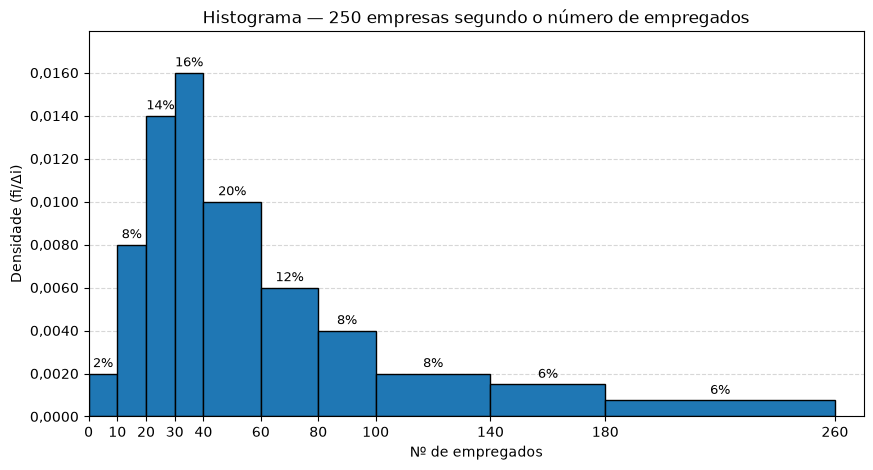

In [23]:
# Questão 4: intervalos de classes desiguais (250 empresas)
# Reutiliza: as funções gráficas (titulo_secao, desenhar_histograma).

# Dados transcritos da tabela do enunciado. Classes [li, ls)
LIMITES_Q4 = [0, 10, 20, 30, 40, 60, 80, 100, 140, 180, 260]
FREQUENCIAS_Q4 = [5, 20, 35, 40, 50, 30, 20, 20, 15, 15]
assert sum(FREQUENCIAS_Q4) == 250, "Deveriam ser 250 empresas"


def tabela_classes_desiguais(limites, frequencias):
    """Para cada classe calcula:
       Δi = ls - li (amplitude)    ni/Δi (densidade de frequência)
       fi = ni / n  (proporção)    fi/Δi (densidade da proporção)"""
    n = sum(frequencias)
    linhas = []
    for li, ls, ni in zip(limites[:-1], limites[1:], frequencias):
        delta = ls - li
        fi = ni / n
        linhas.append({"li": li, "ls": ls, "ni": ni, "delta": delta,
                       "dens_n": ni / delta, "fi": fi, "dens_f": fi / delta})

    print(f"{'Nº de empregados':>16} | {'ni':>3} | {'Δi':>3} | {'ni/Δi':>5} | {'fi':>4} | {'fi/Δi':>6}")
    print("-" * 56)
    for l in linhas:
        print(f"{l['li']:>7} |-- {l['ls']:<4} | {l['ni']:>3} | {l['delta']:>3} | "
              f"{l['dens_n']:>5.2f} | {l['fi']:>4.2f} | {l['dens_f']:>6.4f}")
    print("-" * 56)
    print(f"{'Total':>16} | {n:>3} | {'—':>3} | {'—':>5} | {1:>4.2f} | {'—':>6}")
    return linhas


def analisar_concentracao(linhas):
    """Compara a classe de maior frequência absoluta com as de maior e menor densidade."""
    def classe(l):
        return f"{l['li']} |-- {l['ls']}"

    maior_freq = max(linhas, key=lambda l: l["ni"])
    maior_dens = max(linhas, key=lambda l: l["dens_n"])
    menor_dens = min(linhas, key=lambda l: l["dens_n"])
    print(f"\nMaior frequência absoluta: {classe(maior_freq)} (ni = {maior_freq['ni']})")
    print(f"Maior densidade (ni/Δi):   {classe(maior_dens)} (ni/Δi = {maior_dens['dens_n']:.2f})")
    print(f"Menor densidade (ni/Δi):   {classe(menor_dens)} (ni/Δi = {menor_dens['dens_n']:.2f})")


titulo_secao("Questão 4: intervalos de classes desiguais (250 empresas)")
linhas_q4 = tabela_classes_desiguais(LIMITES_Q4, FREQUENCIAS_Q4)
analisar_concentracao(linhas_q4)

# Histograma: altura = densidade fi/Δi e largura = Δi. Assim, a área de cada retângulo é a proporção fi e a área total é igual a 1 (100%).
densidades = [l["dens_f"] for l in linhas_q4]
area_total = sum(l["dens_f"] * l["delta"] for l in linhas_q4)
print(f"\nÁrea total do histograma: Σ (fi/Δi)·Δi = {area_total:.4f}")

ax = desenhar_histograma(LIMITES_Q4, densidades,
                         "Histograma — 250 empresas segundo o número de empregados",
                         "Nº de empregados", "Densidade (fi/Δi)",
                         rotulos=[f"{l['fi']:.0%}" for l in linhas_q4])
# Ajustes para ficar no mesmo formato da figura do gabarito
ax.set_yticks([i * 0.002 for i in range(9)])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.4f}".replace(".", ",")))
ax.set_xlim(0, LIMITES_Q4[-1] + 10)
plt.show()

**Comparação com o gabarito (Figura 2.19):**
<img src="imagens/4-graph.png" width="600" alt="Gabarito Questão 4">

O histograma gerado coincide com o gabarito: as alturas dos retângulos são as densidades $f_i/\Delta_i$ (de 0,0020 a 0,0160), as larguras são as amplitudes $\Delta_i$ de cada classe e os rótulos indicam as proporções $f_i$ (2%, 8%, 14%, 16%, 20%, 12%, 8%, 8%, 6%, 6%). A área total é igual a 1 (100%).

Como esperado, a classe de maior frequência absoluta é $40 \vdash 60$ ($n_i = 50$), mas a de maior concentração é $30 \vdash 40$ ($n_i/\Delta_i = 4{,}00$), e a de menor concentração é a última, $180 \vdash 260$ ($n_i/\Delta_i \approx 0{,}19$).